# **4 Кейс**

**Описание кейса:** требуется классифицировать риск задержки доставки заказа более чем на 5 минут от обещанного времени на этапе оформления, используя параметры ресторана, рейтинг курьера, погодные условия и пробки.

https://www.kaggle.com/datasets/razanihababdellatif/food-delivery-orders-and-eta-logistics-dataset

## **Импорт библиотек**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## **Загрузка данных**

In [2]:
df = pd.read_csv("food_delivery_orders_dataset.csv")

## **Первичный анализ**

In [3]:
pd.set_option('display.max_columns', None)
df.head()

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,restaurant_primary_category,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,payment_method,tip_amount,distance_km,weather,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,City_C_Area_3,40,Premium,Casual Dining,Healthy,4.4,4,64.82,0,9.07,2.40,0.00,76.29,Credit Card,11.36,1.1,Rain,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,City_A_Area_1,19,Regular,Cafe,Dessert,4.4,2,13.03,0,1.82,0.84,3.25,18.94,Cash,1.09,2.5,Cloudy,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,City_C_Area_3,26,Regular,Fast Food,Dessert,4.8,1,10.12,10,1.28,0.56,7.90,18.85,Cash,0.00,11.8,Cloudy,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,City_A_Area_1,18,New,Fast Food,Local,3.9,1,8.86,10,1.12,0.40,4.70,14.19,Digital Wallet,0.00,5.4,Cloudy,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,City_B_Area_6,20,Regular,Casual Dining,Pizza,3.5,1,15.08,20,1.69,0.65,5.05,19.45,Credit Card,1.70,6.1,Rain,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9


Целевой показатель - **late_delivery**  
Заказ помечается как доставленный с опозданием (late_delivery = 1.0) только в том случае, если фактическое время доставки превышает расчетное более чем на 5 минут

Явно лишние показатели:  
**order_id**, **customer_id**, **restaurant_id** - не несут смысла  
**actual_delivery_time_minutes** - фактическое время доставки не имеет значения, важен факт опоздал курьер или нет

Нужно проверить как **late_delivery** зависит от **driver_id**  

Показатели **order_date**, **order_hour**, **day_of_week**, **is_weekend** можно выразить из **order_timestamp**  
Показатель **city** можно выразить из **delivery_area**.  
Показатель **order_total** выражается из суммы показателей (**subtotal** - **discount_percent**%), **tax_amount**, **service_fee**, **delivery_fee**

In [4]:
df['late_delivery'].value_counts()

late_delivery
0.0    31164
1.0    17968
Name: count, dtype: int64

Есть перевес в сторону записей без опоздания. Записей без опоздания больше примерно в 1.73 раза

In [5]:
print(f"Кол-во строк: {df.shape[0]}")
print(f"Кол-во столбцов: {df.shape[1]}")

Кол-во строк: 50000
Кол-во столбцов: 37


In [6]:
df.dtypes.value_counts()

str        17
float64    12
int64       8
Name: count, dtype: int64

Категориальных параметров - 17  
Непрерывных параметров - 20 (12 + 8)

In [7]:
# Не получилось вывести все колонки через df.info ))
pd.DataFrame({
    "dtype":   df.dtypes,
    "non_null": df.notna().sum(),
    "null":    df.isna().sum(),
    "null_%":  (df.isna().mean() * 100).round(2),
})

,dtype,non_null,null,null_%
order_id,str,50000,0,0.00
customer_id,str,50000,0,0.00
restaurant_id,str,50000,0,0.00
driver_id,str,50000,0,0.00
order_timestamp,str,50000,0,0.00
order_date,str,50000,0,0.00
order_hour,int64,50000,0,0.00
day_of_week,str,50000,0,0.00
is_weekend,int64,50000,0,0.00
city,str,50000,0,0.00


Есть несоответствие типов:  
**order_timestamp** - строка, хотя логичней тип datetime.datetime  
**order_date** - строка, хотя логичней тип datetime.date

## **Анализ непрерывных показателей**

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
order_hour,50000.0,14.465900,5.231155,0.00,11.00,14.000,19.00,23.00
is_weekend,50000.0,0.267120,0.442460,0.00,0.00,0.000,1.00,1.00
customer_age,50000.0,27.686580,7.537796,18.00,21.00,27.000,33.00,55.00
restaurant_rating,50000.0,4.207956,0.450977,2.80,3.90,4.200,4.60,5.00
items_count,50000.0,2.910020,2.029070,1.00,1.00,2.000,4.00,10.00
subtotal,50000.0,30.897938,27.068965,5.10,13.10,22.825,40.12,362.98
discount_percent,50000.0,4.495700,6.430008,0.00,0.00,0.000,10.00,20.00
tax_amount,50000.0,4.128796,3.636275,0.57,1.73,2.890,5.39,50.82
service_fee,50000.0,1.474600,1.378101,0.13,0.58,1.040,1.89,25.21
delivery_fee,50000.0,3.075108,2.299115,0.00,0.00,3.500,4.50,12.00


Аномалий не вижу  
Скорей всего есть выбросы, если смотреть на 75 квартиль и максимальное значение параметров **order_total**, **service_fee**, **restaurant_preparation_time_minutes** и **tip_amount**. Посмотрим на этой подробней при визуализации

## **Анализ категориальных показателей**

In [9]:
df.describe(include=["str"]).T

,count,unique,top,freq
order_id,50000,50000,ORD_000001,1
customer_id,50000,4979,CUS_00001,4510
restaurant_id,50000,250,RES_0001,8837
driver_id,50000,200,DRV_0066,315
order_timestamp,50000,25459,2025-10-19 13:00:00,9
order_date,50000,30,2025-10-23,1741
day_of_week,50000,7,Thursday,8472
city,50000,4,City_A,19888
delivery_area,50000,40,City_A_Area_1,2056
customer_type,50000,3,Regular,25098


Аномалий не вижу

## **Анализ дублей**

In [10]:
df.duplicated().sum()

np.int64(0)

Дублей нет

## **Анализ пропусков**

**tip_amount**, **actual_delivery_time_minutes**, **late_delivery**, **customer_rating** имеют одинаковое количество пропусков - 868  
У **cancellation_reason** 49132 пропусков, что равно 50000-868  

**late_delivery** - целевая параметр, в ней есть пропуски. Мы можем удалить эти строки, так как нам не нужны строки без ответа

Можно предположить что все пропуски в одних и тех же строках, и после очистки строк с пустым **late_delivery** пропуски пропадут  

Проверим строки с пустым **late_delivery**:

In [11]:
df[df["late_delivery"].isna()].head(15)

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,restaurant_primary_category,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,payment_method,tip_amount,distance_km,weather,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
113,ORD_000114,CUS_00378,RES_0085,DRV_0089,2025-10-13 14:55:00,2025-10-13,14,Monday,0,City_A,City_A_Area_4,22,Regular,Fast Food,Local,4.2,2,16.86,0,2.36,0.62,5.60,25.44,Credit Card,NaN,7.2,Rain,High,27,4.8,11,43,NaN,NaN,Cancelled,Driver Unassigned,NaN
185,ORD_000186,CUS_00001,RES_0003,DRV_0079,2025-10-23 09:25:00,2025-10-23,9,Thursday,0,City_C,City_C_Area_9,40,Premium,Cafe,Burger,4.8,6,35.63,0,4.99,1.75,0.00,42.37,Cash,NaN,3.1,Cloudy,Medium,19,4.4,10,27,NaN,NaN,Cancelled,Changed Mind,NaN
194,ORD_000195,CUS_00032,RES_0002,DRV_0050,2025-10-28 10:00:00,2025-10-28,10,Tuesday,0,City_D,City_D_Area_2,27,New,Fast Food,Burger,3.6,2,17.03,0,2.38,1.18,6.20,26.79,Credit Card,NaN,8.4,Rain,Low,49,5.0,12,34,NaN,NaN,Cancelled,Restaurant Unavailable,NaN
247,ORD_000248,CUS_00216,RES_0018,DRV_0105,2025-10-25 11:29:00,2025-10-25,11,Saturday,1,City_B,City_B_Area_5,30,Regular,Casual Dining,Burger,5.0,1,13.03,10,1.64,0.62,4.35,18.34,Credit Card,NaN,4.7,Cloudy,Low,60,4.3,9,23,NaN,NaN,Cancelled,Changed Mind,NaN
257,ORD_000258,CUS_00004,RES_0001,DRV_0018,2025-10-14 14:09:00,2025-10-14,14,Tuesday,0,City_A,City_A_Area_5,19,Regular,Fast Food,Local,3.9,1,9.23,10,1.16,0.52,5.45,15.44,Credit Card,NaN,6.9,Clear,Medium,28,4.9,13,33,NaN,NaN,Cancelled,Restaurant Unavailable,NaN
322,ORD_000323,CUS_00002,RES_0003,DRV_0197,2025-10-03 19:11:00,2025-10-03,19,Friday,0,City_C,City_C_Area_5,28,Premium,Cafe,Burger,4.8,7,39.14,5,5.21,1.20,0.00,43.59,Cash,NaN,2.9,Clear,High,8,4.3,23,31,NaN,NaN,Cancelled,Driver Unassigned,NaN
333,ORD_000334,CUS_00007,RES_0001,DRV_0103,2025-10-03 17:32:00,2025-10-03,17,Friday,0,City_A,City_A_Area_8,18,New,Fast Food,Local,3.9,1,9.24,0,1.29,0.54,4.00,15.07,Credit Card,NaN,4.0,Clear,Medium,33,4.0,7,23,NaN,NaN,Cancelled,Restaurant Unavailable,NaN
344,ORD_000345,CUS_01619,RES_0002,DRV_0100,2025-10-19 12:36:00,2025-10-19,12,Sunday,1,City_D,City_D_Area_5,27,Premium,Fast Food,Burger,3.6,8,63.14,10,7.96,3.53,0.00,68.32,Credit Card,NaN,4.4,Clear,Medium,50,4.1,28,41,NaN,NaN,Cancelled,Changed Mind,NaN
352,ORD_000353,CUS_00101,RES_0001,DRV_0094,2025-10-25 07:29:00,2025-10-25,7,Saturday,1,City_A,City_A_Area_4,27,Regular,Fast Food,Local,3.9,6,54.82,0,7.67,3.30,2.65,68.44,Digital Wallet,NaN,1.3,Clear,Medium,25,4.4,20,25,NaN,NaN,Cancelled,Customer Cancelled,NaN
428,ORD_000429,CUS_07374,RES_0021,DRV_0041,2025-10-09 22:12:00,2025-10-09,22,Thursday,0,City_B,City_B_Area_2,27,Regular,Cafe,Local,4.2,3,18.80,0,2.63,0.68,4.75,26.86,Credit Card,NaN,5.5,Rain,Low,21,4.8,13,25,NaN,NaN,Cancelled,Customer Cancelled,NaN


Для записей у которых **late_delivery** пустой:  
**tip_amount** = NaN  
**actual_delivery_time_minutes** = NaN  
**order_status** = Cancelled  
**cancellation_reason** заполнен  
**customer_rating** = NaN  

Из этого можно сделать вывод: **customer_rating**, **actual_delivery_time_minutes** и **tip_amount** заполняются только после выполнения доставки. Для прогноза будет ли выполнена доставка без опоздания они НЕ нужны  
**cancellation_reason** заполнен только для записей у которых **late_delivery** не заполнен, для обучения нам нужны только записи с заполненным **late_delivery**, этот параметр не нужен  
**order_status** имеет 2 значения **Cancelled** (для записей **late_delivery.isna()**) и **Completed** (для записей **late_delivery.notna()**). Нас интересуют только записи с заполненным **late_delivery**, в этих записях у order_status будет 1 уникальное значение - **Completed**, можно удалить этот параметр

## **Промежуточный итог**

**Размер датасета:**  
Кол-во строк: 50000  
Кол-во столбцов: 37  

Категориальных параметров - 17  
Непрерывных параметров - 20  

Целевой показатель - **late_delivery**  
Есть перевес в сторону записей без опоздания (**late_delivery** = 0). Записей без опоздания больше примерно в 1.73 раза  

Есть несоответствие типов:  
**order_timestamp** - строка, хотя логичней тип datetime.datetime  
**order_date** - строка, хотя логичней тип datetime.date. 

**Дубликатов в датасете нет**

**Пропуски:**
**tip_amount**, **actual_delivery_time_minutes**, **customer_rating** и **late_delivery** имеют одинаковое количество пропусков - 868  
У **cancellation_reason** 49132 пропусков, что равно 50000-868. Там где **late_delivery** = NaN - **cancellation_reason** имеет значение, во всех остальных случаях **cancellation_reason** пустой  

Есть записи с пустой целевой переменной (**late_delivery** = NaN). Нужно будет удалить эти записи из Датасета
Все пропуски в одних и тех же строках, и после очистки строк с пустым **late_delivery** пропуски пропадут. Останутся пропуски в **cancellation_reason**, но об этом ниже  

На этом этапе уже можно выделить **лишние показатели**:  
**order_id**, **customer_id**, **restaurant_id** - не несут смысла для прогноза будет ли доставка выполнена без опоздания  
**actual_delivery_time_minutes** - фактическое время доставки в этой задаче не имеет значения, важен факт опоздал курьер или нет  
**customer_rating**, **actual_delivery_time_minutes** и **tip_amount** заполняются только после выполнения доставки. Для прогноза будет ли доставка выполнена без опоздания они не нужны  
**cancellation_reason** заполнен только для записей у которых **late_delivery** не заполнен, для обучения нам нужны только записи с заполненным **late_delivery**, этот параметр не нужен  
**order_status** имеет 2 значения **Cancelled** (для записей **late_delivery** = NaN) и **Completed** (для всех остальных записей). Нас интересуют только записи с заполненным **late_delivery**, в этих записях у **order_status** будет 1 уникальное значение - **Completed**, можно удалить этот параметр. 

Итого список столбцов на удаление: **order_id**, **customer_id**, **restaurant_id**, **actual_delivery_time_minutes**, **customer_rating**, **tip_amount**, **cancellation_reason**, **order_status**


**Открытые вопросы после первичного анализа:**  
1. Есть ли зависимоть **late_delivery** от **driver_id**?  
2. Показатели **order_date**, **order_hour**, **day_of_week**, **is_weekend** можно выразить из **order_timestamp**. Какие признаки оставить?  
3. Показатель **city** можно выразить из **delivery_area**. Какой признаки оставить?  
4. Показатель **order_total** выражается из суммы показателей (**subtotal** - **discount_percent**%), **tax_amount**, **service_fee**, **delivery_fee**. Какие признаки оставить?  


## **Преобразования после первичного анализа**

Удаление строк с пустым целевым показателем:

In [12]:
df = df[df["late_delivery"].notna()]

Преобразование показателей с датой к типу datetime и date:

In [13]:
df['order_timestamp'] = pd.to_datetime(df['order_timestamp'])
df['order_date'] = pd.to_datetime(df['order_date']).dt.date

Удаление лишних показателей:

In [14]:
df.drop([
    "order_id",
    "customer_id",
    "restaurant_id",
    "actual_delivery_time_minutes",
    "customer_rating",
    "tip_amount",
    "cancellation_reason",
    "order_status",
], axis=1, inplace=True)

Проверка текущего размера датасета и пропусков:

In [15]:
print(f"Кол-во строк: {df.shape[0]}")
print(f"Кол-во столбцов: {df.shape[1]}")

pd.DataFrame({
    "dtype":   df.dtypes,
    "null":    df.isna().sum()
})

Кол-во строк: 49132
Кол-во столбцов: 29


,dtype,null
driver_id,str,0
order_timestamp,datetime64[us],0
order_date,object,0
order_hour,int64,0
day_of_week,str,0
is_weekend,int64,0
city,str,0
delivery_area,str,0
customer_age,int64,0
customer_type,str,0


## **Анализ выбросов**

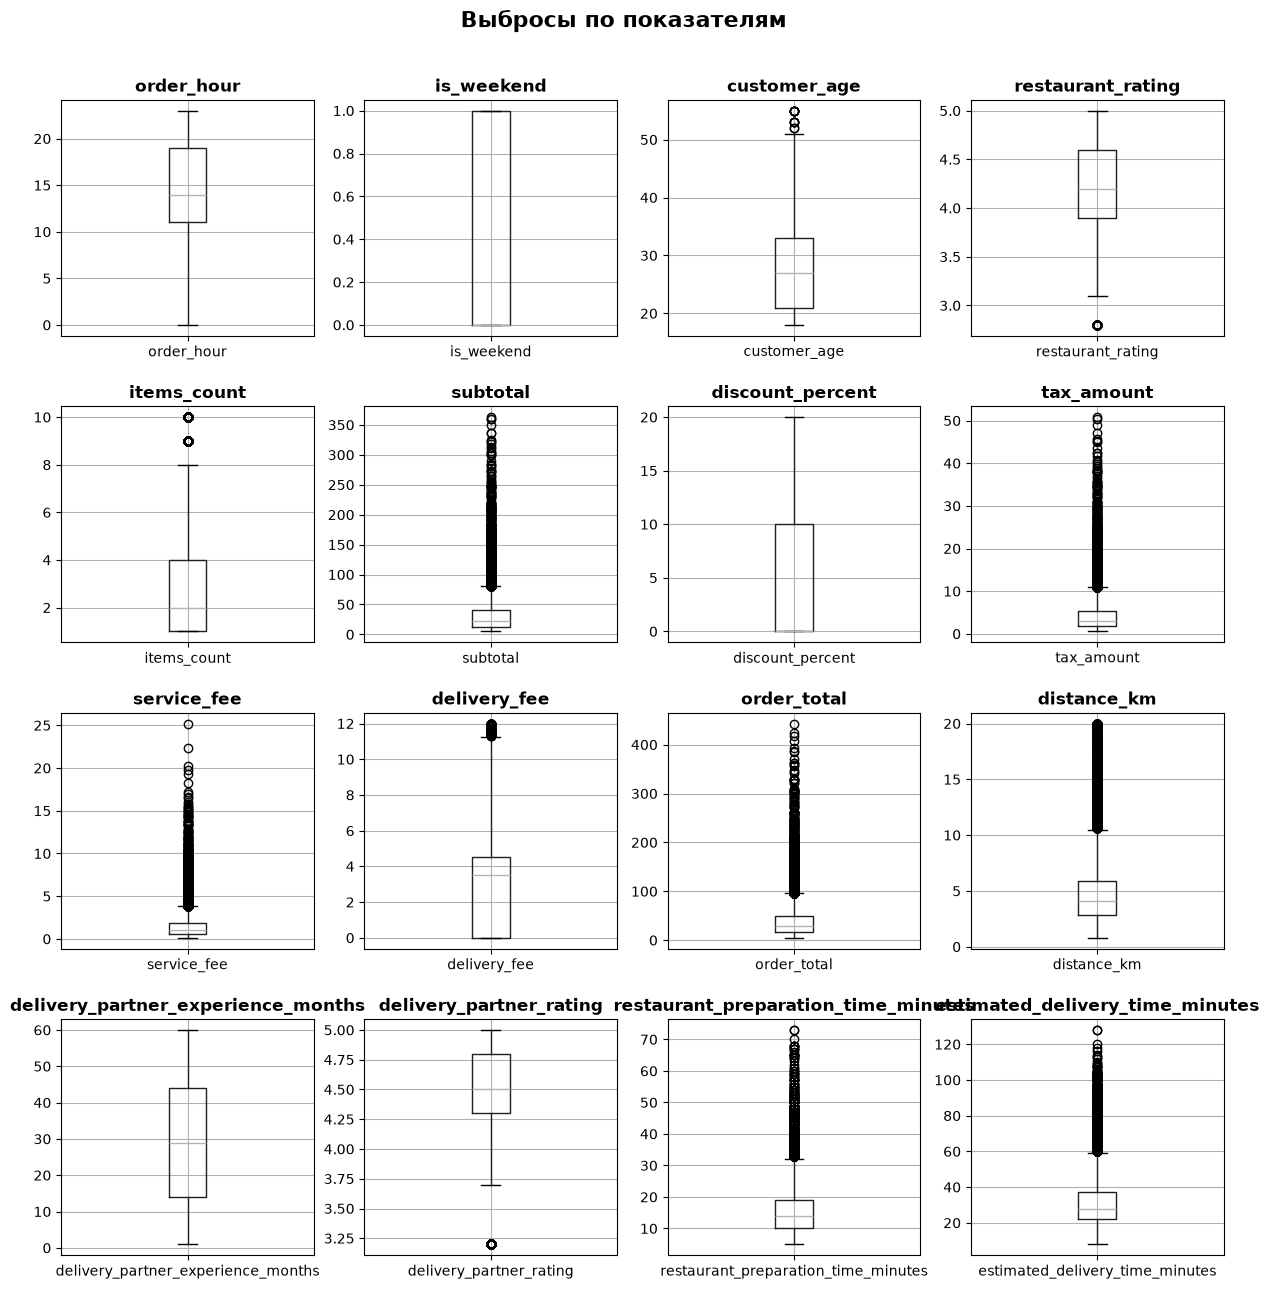

In [16]:
numeric_columns = [
    'order_hour',
    'is_weekend',
    'customer_age',
    'restaurant_rating',
    'items_count',
    'subtotal',
    'discount_percent',
    'tax_amount',
    'service_fee',
    'delivery_fee',
    'order_total',
    'distance_km',
    'delivery_partner_experience_months',
    'delivery_partner_rating',
    'restaurant_preparation_time_minutes',
    'estimated_delivery_time_minutes',
]

fig, axes = plt.subplots(4, 4, figsize=(15, 15))
axes = axes.flatten()

for idx, col in enumerate(numeric_columns):
    ax = axes[idx]
    df.boxplot(column=col, ax=ax)
    ax.set_xlabel('')
    ax.set_title(col, fontsize=12, fontweight='bold')

plt.suptitle('Выбросы по показателям', fontsize=16, fontweight='bold', y=.94)
plt.subplots_adjust(
    wspace=0.2,
    hspace=0.3
)
plt.show()

**Вывод:**  

## **Одномерный анализ**

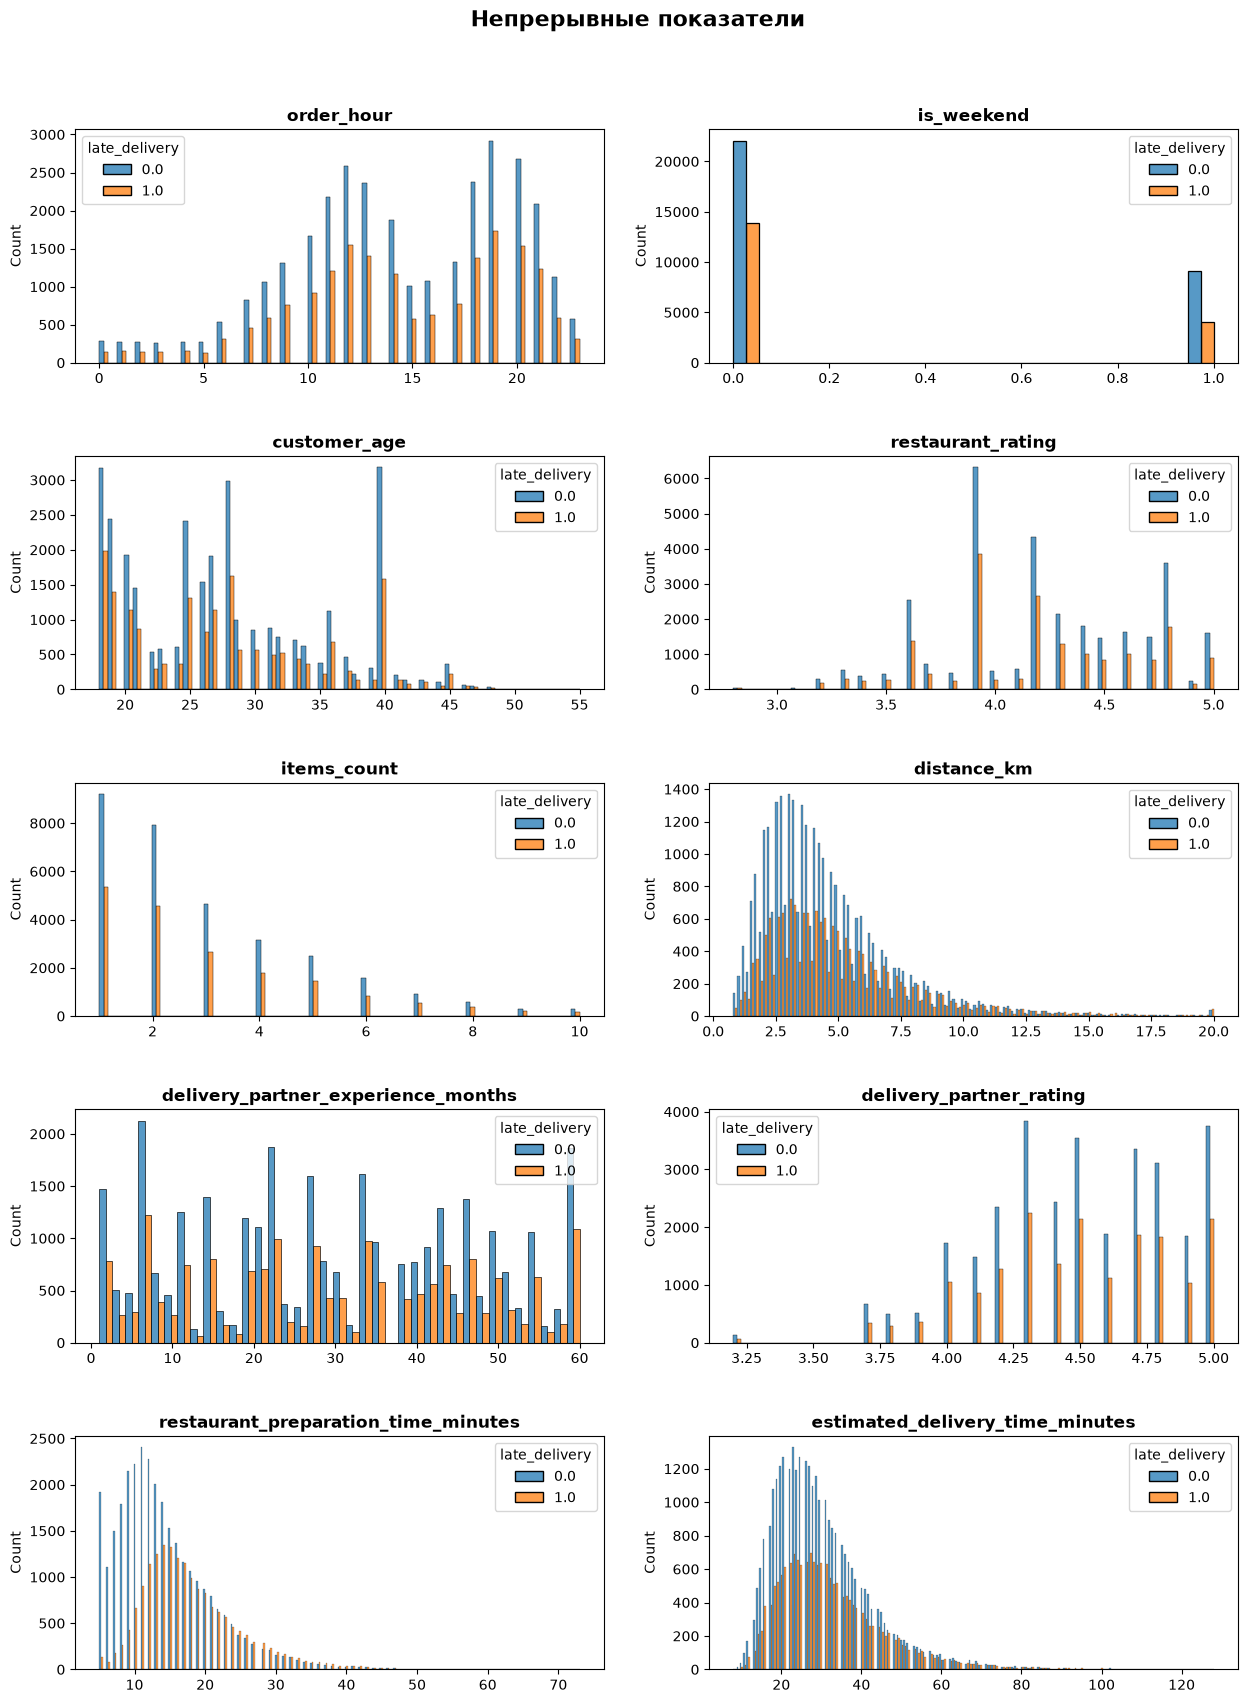

In [17]:
numeric_columns = [
    'order_hour',
    'is_weekend',
    'customer_age',
    'restaurant_rating',
    'items_count',
    'distance_km',
    'delivery_partner_experience_months',
    'delivery_partner_rating',
    'restaurant_preparation_time_minutes',
    'estimated_delivery_time_minutes',
]

fig, axes = plt.subplots(5, 2, figsize=(15, 20))
axes = axes.flatten()

for idx, col in enumerate(numeric_columns):
    ax = axes[idx]
    sns.histplot(
        data=df,
        x=col,
        hue='late_delivery',
        bins="auto",
        multiple='dodge',
        ax=ax
    )
    ax.set_xlabel('')
    ax.set_title(col, fontsize=12, fontweight='bold')

plt.suptitle('Непрерывные показатели', fontsize=16, fontweight='bold', y=.94)
plt.subplots_adjust(
    wspace=0.2,
    hspace=0.4
)
plt.show()

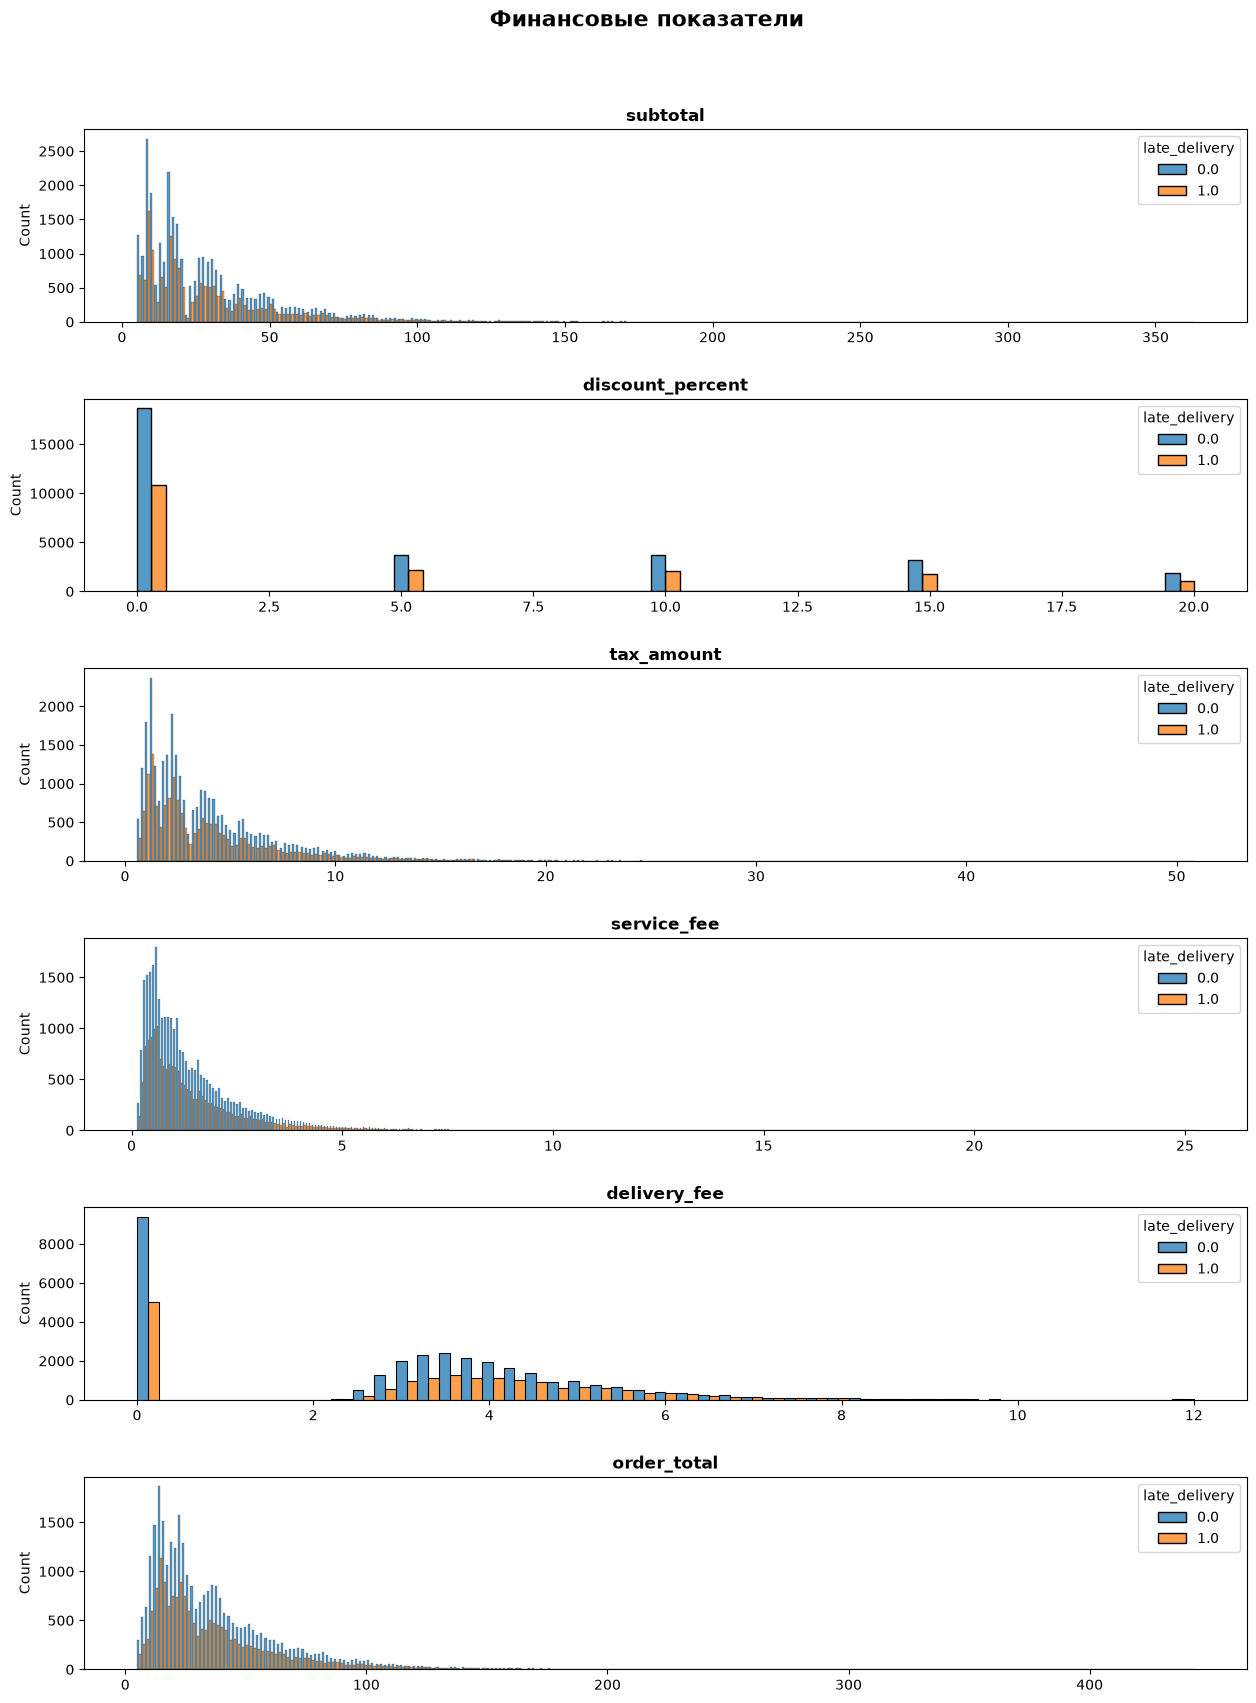

In [18]:
numeric_columns = [
    'subtotal',
    'discount_percent',
    'tax_amount',
    'service_fee',
    'delivery_fee',
    'order_total',
]

fig, axes = plt.subplots(6, 1, figsize=(15, 20))
axes = axes.flatten()

for idx, col in enumerate(numeric_columns):
    ax = axes[idx]
    sns.histplot(
        data=df,
        x=col,
        hue='late_delivery',
        bins="auto",
        multiple='dodge',
        ax=ax
    )
    ax.set_xlabel('')
    ax.set_title(col, fontsize=12, fontweight='bold')

plt.suptitle('Финансовые показатели', fontsize=16, fontweight='bold', y=.94)
plt.subplots_adjust(
    wspace=0.2,
    hspace=0.4
)
plt.show()

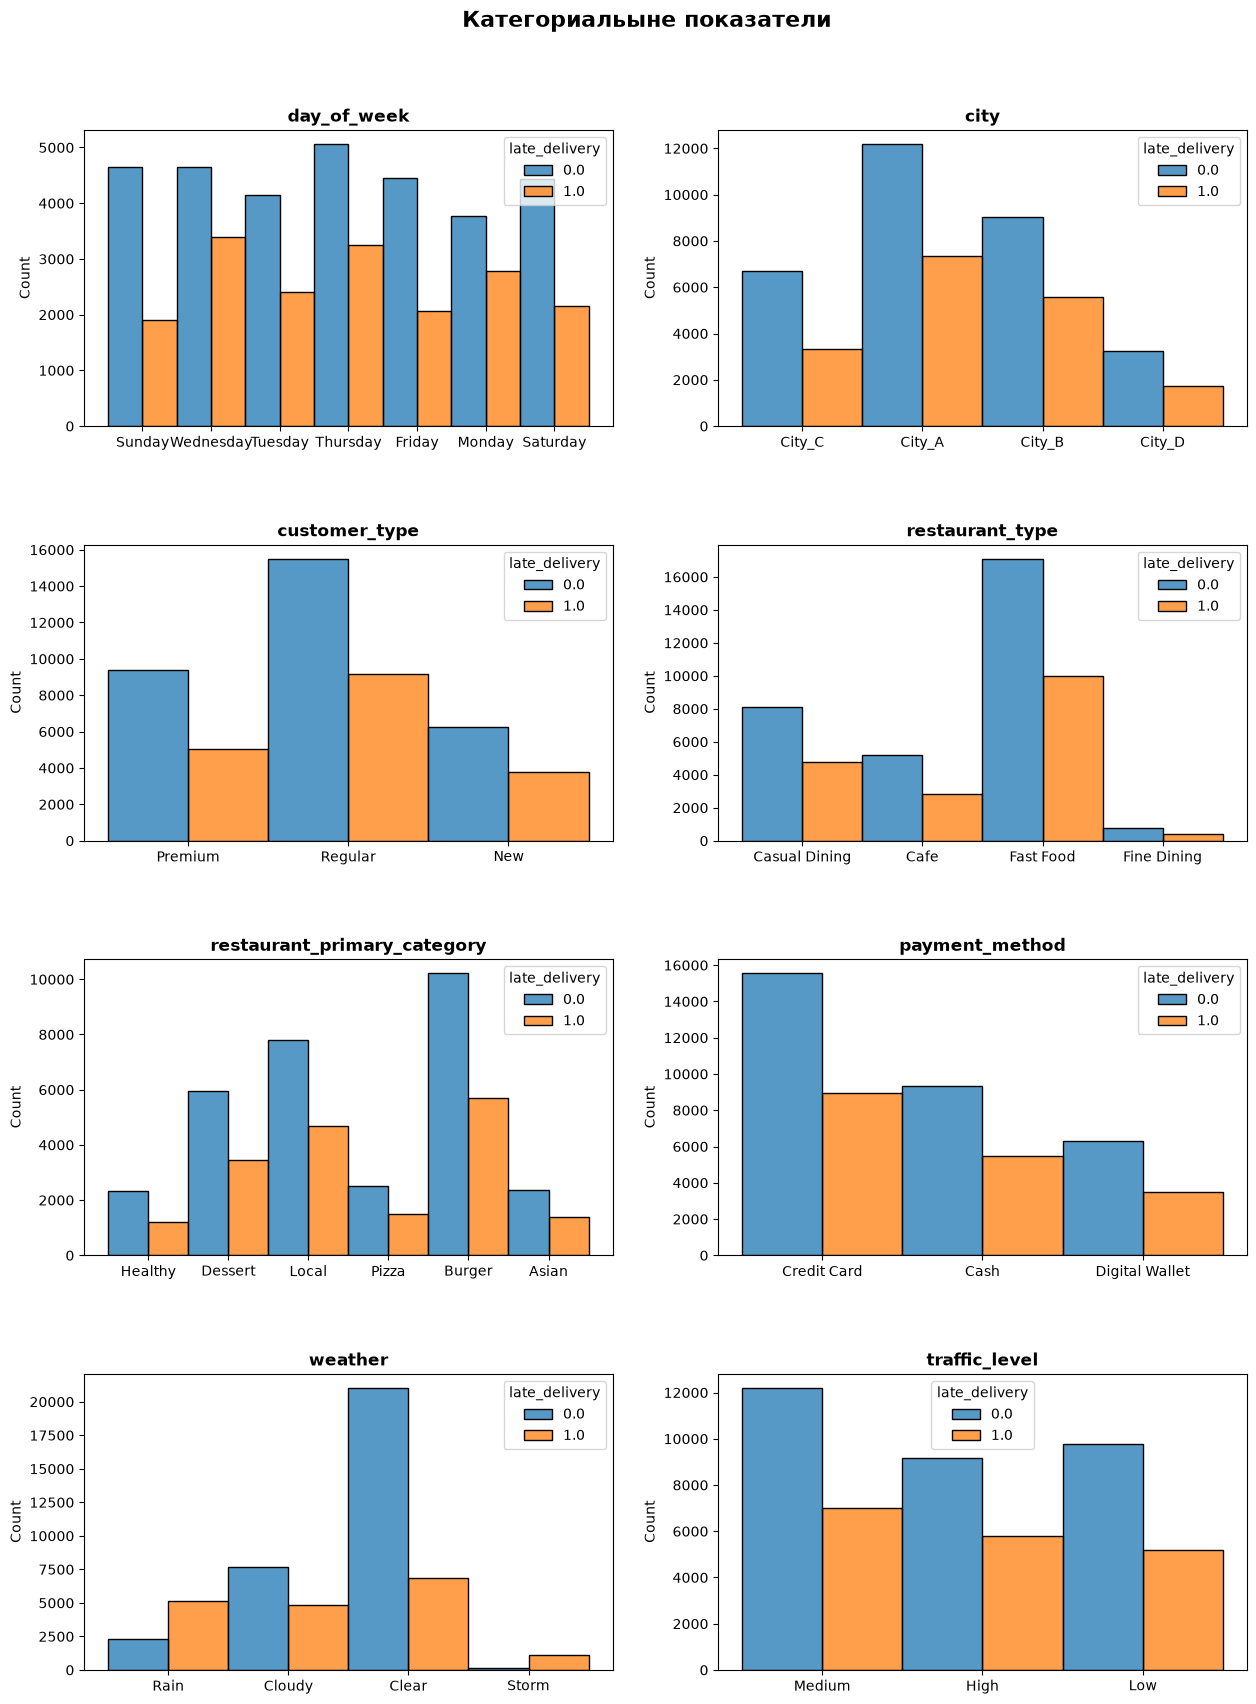

In [19]:
str_columns = [
    'day_of_week',
    'city',
    'customer_type',
    'restaurant_type',
    'restaurant_primary_category',
    'payment_method',
    'weather',
    'traffic_level',
]

fig, axes = plt.subplots(4, 2, figsize=(15, 20))
axes = axes.flatten()

for idx, col in enumerate(str_columns):
    ax = axes[idx]
    sns.histplot(
        data=df,
        x=col,
        hue='late_delivery',
        bins="auto",
        multiple='dodge',
        ax=ax
    )
    ax.set_xlabel('')
    ax.set_title(col, fontsize=12, fontweight='bold')

plt.suptitle('Категориальыне показатели', fontsize=16, fontweight='bold', y=.94)
plt.subplots_adjust(
    wspace=0.2,
    hspace=0.4
)
plt.show()

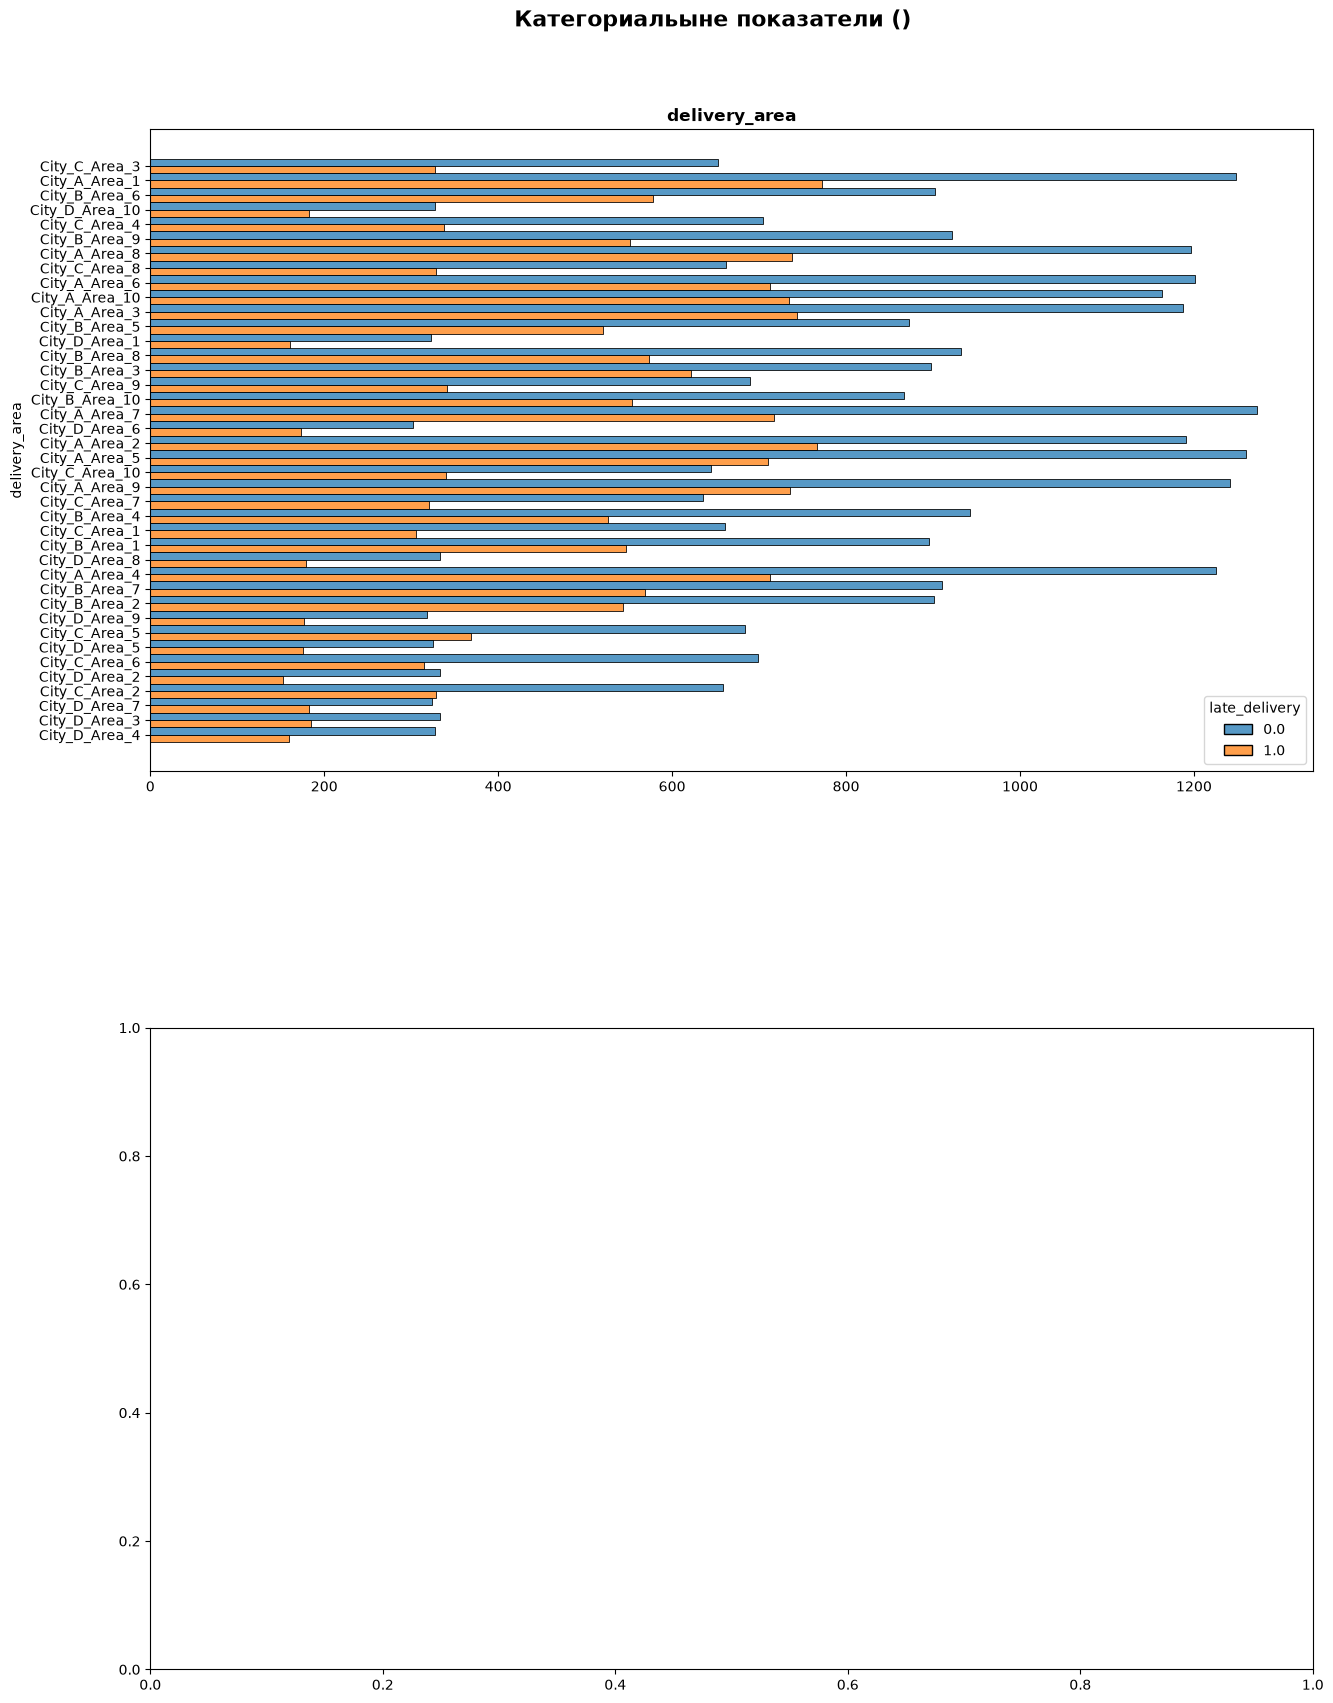

In [20]:
str_columns = [
    # 'driver_id',
    'delivery_area',
]

fig, axes = plt.subplots(2, 1, figsize=(15, 20))
axes = axes.flatten()

for idx, col in enumerate(str_columns):
    ax = axes[idx]
    sns.histplot(
        data=df,
        y=col,
        hue='late_delivery',
        bins="auto",
        multiple='dodge',
        binwidth=10,
        ax=ax
    )
    ax.set_xlabel('')
    ax.set_title(col, fontsize=12, fontweight='bold')

plt.suptitle('Категориальыне показатели ()', fontsize=16, fontweight='bold', y=.94)
plt.subplots_adjust(
    wspace=0.2,
    hspace=0.4
)
plt.show()

## **Многомерный анализ**

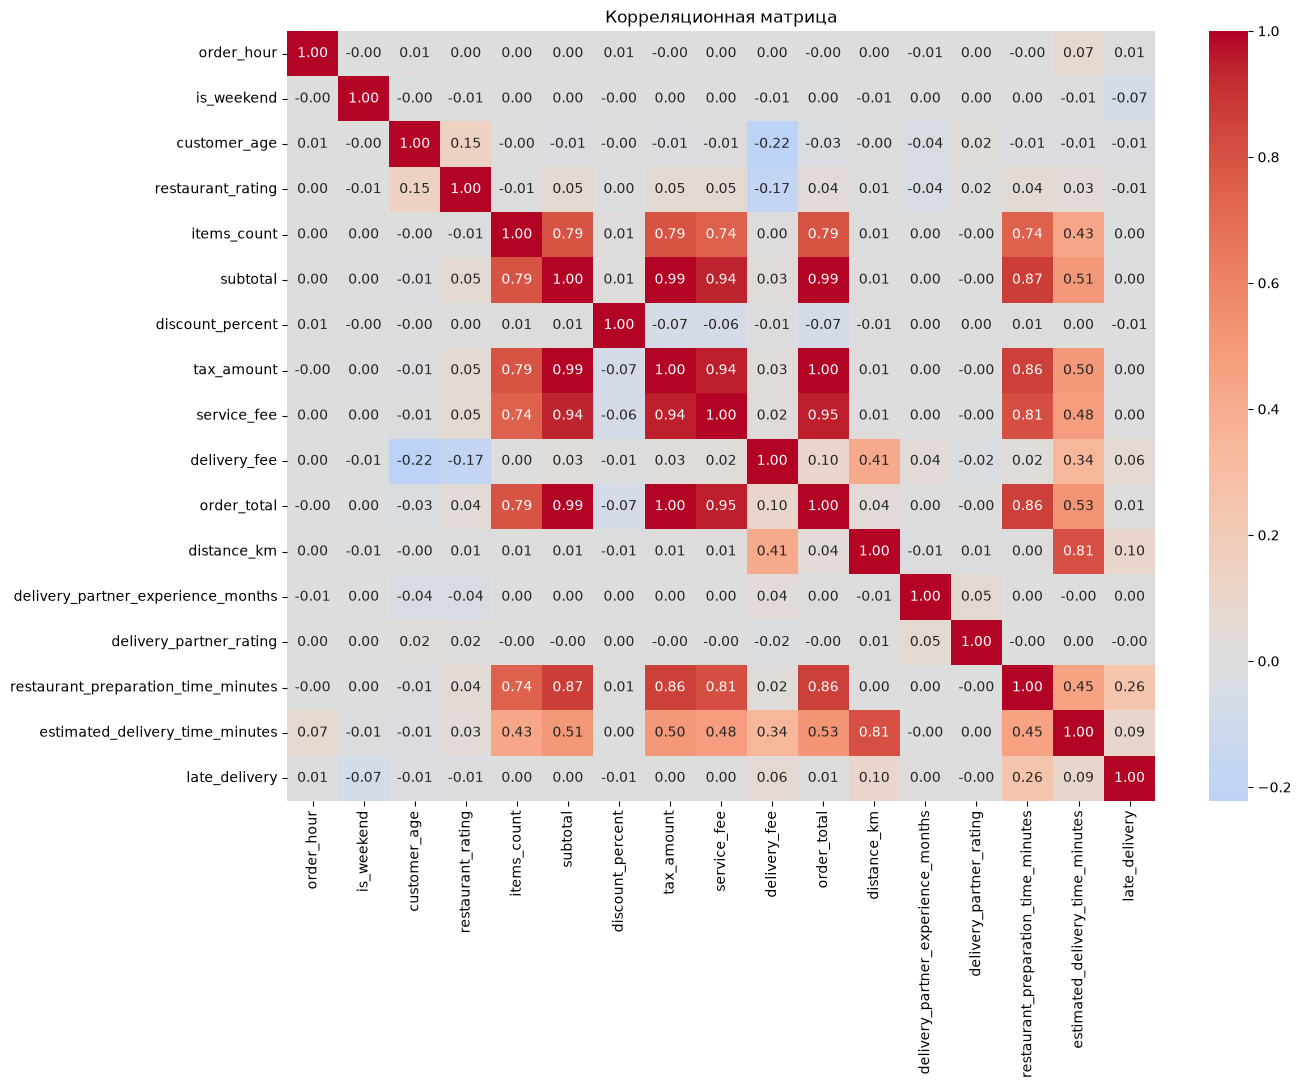

In [21]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title('Корреляционная матрица')
plt.show()

In [22]:
# Pairplot
# sns.pairplot(df, diag_kind='kde',
#              plot_kws={'alpha': 0.5, 's': 10},
#              diag_kws={'linewidth': 2})
# plt.suptitle('Pairplot: Взаимосвязи между ключевыми характеристиками',
#              fontsize=14, fontweight='bold', y=1.02)
# plt.show()